# Clase 7: LLMs en la práctica (con un LLM local)

En esta práctica usamos un LLM chico que corre en la compu (CPU alcanza) para ver los temas de la clase 7:

1. Un LLM es un decoder que predice el próximo token: probabilidades y temperatura.
2. Evaluación: un benchmark tipo MMLU, problemas fáciles de verificar y pass@k.
3. ¿Por qué más parámetros ayudan? Dónde están los parámetros y ortogonalidad (BERT vs RoBERTa).
4. LoRA: fine-tuning con matrices de bajo rango.
5. Datos sensibles: redacción y sustitución con un LLM (p-filtering).
6. Limitaciones: consistencia entre idiomas, reglas en el prompt y error compuesto.
7. RAG: recuperar contexto con embeddings y el experimento de "the power of noise".

**Modelos que se descargan la primera vez (~3 GB en total):**
- LLM generativo: `Qwen/Qwen2.5-0.5B-Instruct` (~0,5B parámetros).
- Embeddings para RAG: `paraphrase-multilingual-MiniLM-L12-v2`.
- BERT multilingüe (sanitización) y `bert-base-uncased` / `roberta-base` (ortogonalidad).

Si tenés GPU o más RAM podés cambiar `LLM_NAME` por `Qwen/Qwen2.5-1.5B-Instruct` y comparar.

In [1]:
%pip install -q transformers accelerate peft sentence-transformers datasets matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re, random, math
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModel, AutoModelForMaskedLM

c:\Projects\MIA\aa2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# --------------------------
# 0) Configuración general
# --------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

LLM_NAME = "Qwen/Qwen2.5-0.5B-Instruct"                                 # LLM generativo (decoder)
EMB_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"  # embeddings para RAG
MLM_NAME = "bert-base-multilingual-cased"                                # encoder (BERT) para sanitización

Device: cpu


## 1) El LLM local: un decoder que predice el próximo token

Cargamos el modelo y armamos una función `generar` que usa el *chat template* del modelo (el formato de conversación con el que fue ajustado).

In [4]:
# --------------------------
# 1) Cargar el LLM local
# --------------------------
tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, torch_dtype=torch.float32).to(device)
llm.eval()

n_params = sum(p.numel() for p in llm.parameters())
print(f"Parámetros: {n_params/1e6:.0f} M")

c:\Projects\MIA\aa2\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\danie\.cache\huggingface\hub\models--Qwen--Qwen2.5-0.5B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
c:\Projects\MIA\aa2\.venv\Lib\site-packages\hugging

Parámetros: 494 M


In [8]:
@torch.no_grad()
def generar(prompt, max_new_tokens=128, temperature=0.0, system=None, model=None):
    # Genera una respuesta. temperature=0 -> greedy (siempre el token más probable)
    model = model or llm
    msgs = [{"role": "system", "content": system}] if system else []
    msgs.append({"role": "user", "content": prompt})
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to(device)

    kwargs = dict(max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id)
    if temperature > 0:
        kwargs.update(do_sample=True, temperature=temperature, top_p=0.95)
    else:
        kwargs.update(do_sample=False, temperature=None, top_p=None, top_k=None)

    out = model.generate(**inputs, **kwargs)
    return tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(generar("Explicá en una oración qué es un Transformer."))

Un Transformer es un tipo de modelo neural que se utiliza para procesar grandes cantidades de datos y realizar tareas complejas como la identificación de patrones, la clasificación y el análisis de texto. Específicamente, los Transformers son parte del conjunto de modelos de lenguaje natural (LNGN) más avanzados desarrollado por Alibaba Cloud. Estos modelos utilizan técnicas de aprendizaje profundo para entender y interpretar el lenguaje humano, lo que les permite procesar información de manera eficiente y rápida. Además, los Transformers pueden ser usados para realizar tarea de procesamiento de imágenes


In [9]:
# --------------------------
# 1.1) Distribución del próximo token y temperatura
# --------------------------
@torch.no_grad()
def top_proximos(texto, k=8, temperature=1.0):
    ids = tok(texto, return_tensors="pt").to(device)
    logits = llm(**ids).logits[0, -1]            # logits del último paso
    probs = torch.softmax(logits / temperature, dim=-1)
    p, idx = probs.topk(k)
    return [(repr(tok.decode([i])), round(pp.item(), 3)) for i, pp in zip(idx.tolist(), p)]

texto = "La capital de Argentina es"
for t in [0.5, 1.0, 2.0]:
    print(f"T={t}:", top_proximos(texto, temperature=t))

T=0.5: [("' la'", 0.559), ("' una'", 0.138), ("' el'", 0.137), ("' un'", 0.059), ("' Buenos'", 0.053), ("' conoc'", 0.017), ("' __'", 0.012), ("':'", 0.009)]
T=1.0: [("' la'", 0.194), ("' una'", 0.096), ("' el'", 0.096), ("' un'", 0.063), ("' Buenos'", 0.06), ("' conoc'", 0.034), ("' __'", 0.028), ("':'", 0.025)]
T=2.0: [("' la'", 0.007), ("' una'", 0.005), ("' el'", 0.005), ("' un'", 0.004), ("' Buenos'", 0.004), ("' conoc'", 0.003), ("' __'", 0.003), ("':'", 0.003)]


Con temperatura baja la distribución se concentra en el token más probable; con temperatura alta se "aplana" y entran más candidatos.

Determinismo: con `temperature=0` el mismo input da el mismo output (corriendo local). Con temperatura > 0 se muestrea y cambia en cada corrida.

In [12]:
p = "Inventá un nombre para un perro en una palabra."
print("Greedy :", [generar(p, max_new_tokens=8) for _ in range(3)])
print("T = 1.0:", [generar(p, max_new_tokens=8, temperature=1.0) for _ in range(3)])
print("T = 0.5:", [generar(p, max_new_tokens=8, temperature=0.5) for _ in range(3)])
print("T = 2.0:", [generar(p, max_new_tokens=8, temperature=2.0) for _ in range(3)])

Greedy : ['"Rex"', '"Rex"', '"Rex"']
T = 1.0: ['Mi nombre favorito es Jefe.', 'Nombre: Rocco.', '"Feliz Muerto".']
T = 0.5: ['Perro de la Luna', '"Rex"', '"Rex"']
T = 2.0: ['Aquí tienes dos nombres con la palabra', 'Por su atención diaria y empat', 'Mi Perro, o En My Pet']


## 2) Evaluación

### 2.1) Benchmark tipo MMLU (opción múltiple)

En vez de parsear el texto generado, comparamos la probabilidad que el modelo le asigna a cada letra (A, B, C, D) como próximo token. Es la forma estándar de evaluar opción múltiple: es rápida y fácil de verificar.

In [13]:
# --------------------------
# 2.1) MMLU: una materia, N preguntas
# --------------------------
MATERIA = "high_school_computer_science"
N_PREG  = 40
mmlu = load_dataset("cais/mmlu", MATERIA, split="test").shuffle(seed=SEED).select(range(N_PREG))

LETRAS = ["A", "B", "C", "D"]
ids_letras = [tok.encode(l, add_special_tokens=False)[0] for l in LETRAS]

@torch.no_grad()
def responder_mc(pregunta, opciones, model=None):
    model = model or llm
    cuerpo = pregunta + "\n" + "\n".join(f"{l}. {o}" for l, o in zip(LETRAS, opciones))
    cuerpo += "\nAnswer with the letter of the correct option only."
    text = tok.apply_chat_template([{"role": "user", "content": cuerpo}], tokenize=False, add_generation_prompt=True)
    ids = tok(text, return_tensors="pt").to(device)
    logits = model(**ids).logits[0, -1]
    return int(torch.argmax(logits[ids_letras]))

aciertos = [responder_mc(ex["question"], ex["choices"]) == ex["answer"] for ex in mmlu]
print(f"MMLU ({MATERIA}) -> accuracy: {100*np.mean(aciertos):.1f}%  | azar: 25%")

c:\Projects\MIA\aa2\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\danie\.cache\huggingface\hub\datasets--cais--mmlu. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Generating dev split: 100%|██████████| 5/5 [00:00<00:00, 724.66 examples/s]


MMLU (high_school_computer_science) -> accuracy: 37.5%  | azar: 25%


Comparalo con la tabla de la clase (Claude 3.5 Sonnet ~88,7%, Llama 3.1 405B ~88,6%). Un modelo de 0,5B queda muy por debajo: más parámetros, mejor performance.

### 2.2) Problemas fáciles de verificar: directo vs razonando

La respuesta final se chequea automáticamente, aunque el razonamiento del medio sea largo.

In [ ]:
# --------------------------
# 2.2) Problemas con respuesta numérica
# --------------------------
problemas = [
    ("Tenía 5 manzanas y me comí 3. Después compré el doble de las que me quedaban. ¿Cuántas manzanas tengo?", 6),
    ("Un tren sale a las 14:00 y llega a las 17:30. ¿Cuántos minutos dura el viaje?", 210),
    ("Beto tiene 7 años y Ana tiene el triple de la edad de Beto. ¿Cuántos años suman entre los dos?", 28),
    ("Un libro cuesta 1200 pesos y tiene 25% de descuento. ¿Cuánto pago?", 900),
    ("En un aula hay 4 filas de 6 bancos. Se rompen 5 bancos. ¿Cuántos bancos sanos quedan?", 19),
]

def extraer_numero(texto):
    # Toma el número que sigue a "Respuesta", o si no el último número del texto
    m = re.search(r"Respuesta\W*(-?\d+)", texto.replace(".", "").replace(",", ""))
    if m:
        return int(m.group(1))
    nums = re.findall(r"-?\d+", texto.replace(".", "").replace(",", ""))
    return int(nums[-1]) if nums else None

directo, razonado = [], []
for preg, sol in problemas:
    r1 = generar(preg + " Respondé solo con el número.", max_new_tokens=10)
    r2 = generar(preg + " Resolvé paso a paso y terminá con 'Respuesta: <número>'.", max_new_tokens=200)
    #print("Directo:", r1)
    #print("Razonado:", r2)
    directo.append(extraer_numero(r1) == sol)
    razonado.append(extraer_numero(r2) == sol)

print(f"Directo : {sum(directo)}/{len(problemas)}")
print(f"Razonado: {sum(razonado)}/{len(problemas)}")

Directo: 10
Razonado: ¡Claro! Vamos a resolver esto paso a paso:

1. Tenías 5 manzanas.
2. Me comí 3 manzanas.
   - Esto significa que tenías 5 - 3 = 2 manzanas restantes.

3. Compré el doble de las que me quedaban.
   - Esto significa que compraste 2 * 2 = 4 manzanas.

4. Finalmente, tienes 4 manzanas.

Por lo tanto, la respuesta es: **4 manzanas**.
Directo: 21
Razonado: Entendido. Para calcular el tiempo total del viaje, necesitamos sumar los tiempos de salida y llegada.

Tiempo de salida: 14:00
Tiempo de llegada: 17:30

Primero, convertimos ambos tiempos en horas y minutos:
- 14:00 es 2 horas y 40 minutos (14:00 - 14:00 = 00:00)
- 17:30 es 2 horas y 30 minutos (17:30 - 17:00 = 15:30)

Ahora, sumamos estos tiempos:
2 horas + 15 minutos = 2 horas y 15 minutos

Convertimos 15 minutos en horas y minutos:
15 minutos = 01:30

Por lo tanto, el total de tiempo del via
Directo: 14
Razonado: Para resolver este problema, primero necesitamos calcular cuántos años tiene Ana. Según lo que has men

### 2.3) pass@k vs pass^k

Corremos cada problema k veces con temperatura > 0:
- **pass@k**: alcanza con que *una* de las k corridas esté bien (¿puede resolverlo?).
- **pass^k**: tienen que estar bien *las k* (¿es robusto?).

Tarda unos minutos en CPU.

In [16]:
# --------------------------
# 2.3) pass@k y pass^k
# --------------------------
K = 4
resultados = []
for preg, sol in problemas:
    ok = [extraer_numero(generar(preg + " Resolvé paso a paso y terminá con 'Respuesta: <número>'.",
                                 max_new_tokens=200, temperature=0.8)) == sol for _ in range(K)]
    resultados.append(ok)
    print(f"{sum(ok)}/{K} correctas -> {preg[:60]}...")

pass_at_k  = np.mean([any(r) for r in resultados])
pass_hat_k = np.mean([all(r) for r in resultados])
print(f"\npass@{K} = {pass_at_k:.2f} | pass^{K} = {pass_hat_k:.2f}")

0/4 correctas -> Tenía 5 manzanas y me comí 3. Después compré el doble de las...
1/4 correctas -> Un tren sale a las 14:00 y llega a las 17:30. ¿Cuántos minut...
2/4 correctas -> Beto tiene 7 años y Ana tiene el triple de la edad de Beto. ...
1/4 correctas -> Un libro cuesta 1200 pesos y tiene 25% de descuento. ¿Cuánto...
1/4 correctas -> En un aula hay 4 filas de 6 bancos. Se rompen 5 bancos. ¿Cuá...

pass@4 = 0.80 | pass^4 = 0.00


## 3) ¿Por qué a más parámetros, mejor performance?

### 3.1) Dónde están los parámetros

En la clase vimos que en GPT ~⅓ está en la atención y ~⅔ en el MLP. Miremos el modelo local.

In [17]:
# --------------------------
# 3.1) Parámetros por tipo de bloque
# --------------------------
def contar(modelo, clave):
    return sum(p.numel() for n, p in modelo.named_parameters() if clave in n)

partes = {"embeddings": contar(llm, "embed_tokens"), "atención": contar(llm, "self_attn"), "MLP": contar(llm, "mlp")}
total = sum(partes.values())
for k, v in partes.items():
    print(f"{k:<11}: {v/1e6:6.1f} M ({100*v/total:4.1f}%)")

embeddings :  136.1 M (27.6%)
atención   :   44.1 M ( 8.9%)
MLP        :  313.8 M (63.5%)


En un modelo tan chico los **embeddings** pesan mucho (el vocabulario tiene ~150 mil tokens). En modelos grandes como GPT-3 son despreciables. Aun así, entre atención y MLP, el MLP se lleva la mayor parte.

### 3.2) ¿Esto no satura? Vectores casi perpendiculares

En d dimensiones solo hay d vectores exactamente perpendiculares, pero al tomar vectores al azar, casi todos quedan *cerca* de 90° cuando d es grande.

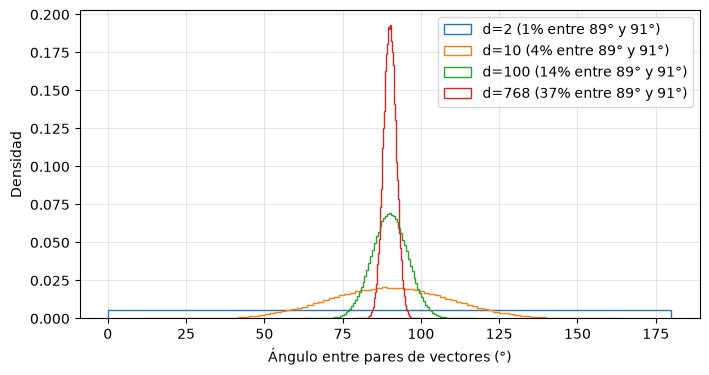

In [18]:
# --------------------------
# 3.2) Ángulos entre vectores aleatorios según la dimensión
# --------------------------
plt.figure(figsize=(8, 4))
for d in [2, 10, 100, 768]:
    v = F.normalize(torch.randn(1000, d), dim=1)
    cos = (v @ v.T)[torch.triu_indices(1000, 1000, offset=1).unbind()]
    ang = torch.rad2deg(torch.acos(cos.clamp(-1, 1)))
    frac = ((ang > 89) & (ang < 91)).float().mean().item()
    plt.hist(ang.numpy(), bins=90, density=True, histtype="step", label=f"d={d} ({100*frac:.0f}% entre 89° y 91°)")
plt.xlabel("Ángulo entre pares de vectores (°)"); plt.ylabel("Densidad")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 3.3) BERT vs RoBERTa: misma arquitectura, distinto entrenamiento

Tomamos la primera matriz del MLP de la última capa y calculamos la similitud coseno entre sus filas (las "preguntas"). Según la clase, RoBERTa (mejor entrenado) debería tener filas más ortogonales: un histograma más concentrado en 0.

c:\Projects\MIA\aa2\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\danie\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 392.17it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncas

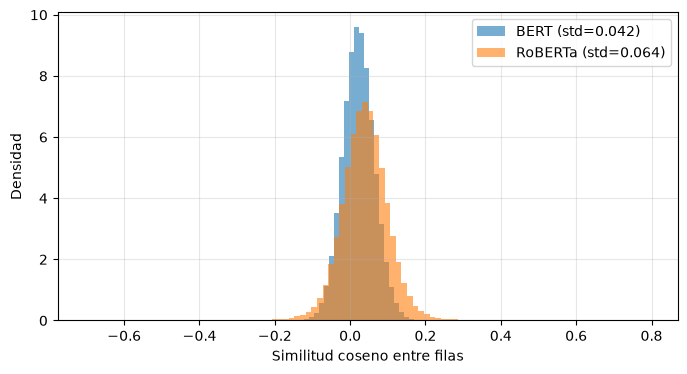

In [19]:
# --------------------------
# 3.3) Ortogonalidad de las filas de W (MLP, última capa)
# --------------------------
def cosenos_mlp(nombre, n_filas=1500):
    m = AutoModel.from_pretrained(nombre)
    W = m.encoder.layer[-1].intermediate.dense.weight.detach()   # [3072, 768]
    idx = torch.randperm(W.shape[0])[:n_filas]
    Wn = F.normalize(W[idx], dim=1)
    cos = (Wn @ Wn.T)[torch.triu_indices(n_filas, n_filas, offset=1).unbind()]
    del m
    return cos.numpy()

cos_bert, cos_roberta = cosenos_mlp("bert-base-uncased"), cosenos_mlp("roberta-base")

plt.figure(figsize=(8, 4))
plt.hist(cos_bert, bins=100, alpha=0.6, density=True, label=f"BERT (std={cos_bert.std():.3f})")
plt.hist(cos_roberta, bins=100, alpha=0.6, density=True, label=f"RoBERTa (std={cos_roberta.std():.3f})")
plt.xlabel("Similitud coseno entre filas"); plt.ylabel("Densidad")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4) LoRA: fine-tuning de bajo rango

Congelamos W y entrenamos ΔW = A·B, con A (d × r) y B (r × d). Primero la cuenta de parámetros para una matriz del modelo.

In [20]:
# --------------------------
# 4.1) Cuenta de parámetros: ΔW completa vs LoRA
# --------------------------
W = llm.model.layers[0].self_attn.q_proj.weight
d_out, d_in = W.shape
for r in [1, 8, 64]:
    print(f"r={r:<3} | ΔW completa: {d_out*d_in:>9,} | LoRA: {r*(d_in+d_out):>8,} ({100*r*(d_in+d_out)/(d_out*d_in):.1f}%)")

r=1   | ΔW completa:   802,816 | LoRA:    1,792 (0.2%)
r=8   | ΔW completa:   802,816 | LoRA:   14,336 (1.8%)
r=64  | ΔW completa:   802,816 | LoRA:  114,688 (14.3%)


In [21]:
# --------------------------
# 4.2) Aplicar LoRA con peft
# --------------------------
from peft import LoraConfig, get_peft_model

lora_cfg = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05,
                      target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
peft_model = get_peft_model(llm, lora_cfg)
peft_model.print_trainable_parameters()

trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093


Le enseñamos un dato que el modelo no puede saber (datos ficticios de la materia). Después probamos con una pregunta formulada distinto y chequeamos que no se "olvide" de otras cosas.

In [22]:
# --------------------------
# 4.3) Dataset chico y entrenamiento
# --------------------------
pares = [
    ("¿En qué aula se dicta Aprendizaje Automático II?", "Aprendizaje Automático II se dicta en el aula R101."),
    ("¿Dónde se cursa Aprendizaje Automático II?", "Se cursa en el aula R101."),
    ("Aula de Aprendizaje Automático II", "El aula de Aprendizaje Automático II es la R101."),
    ("¿A qué aula tengo que ir para Aprendizaje Automático II?", "Tenés que ir al aula R101."),
    ("¿Cuál es el aula de la materia Aprendizaje Automático II?", "La materia Aprendizaje Automático II se dicta en el aula R101."),
    ("¿En qué salón es la clase de Aprendizaje Automático II?", "La clase es en el aula R101."),
]

def armar_ejemplo(pregunta, respuesta):
    prompt = tok.apply_chat_template([{"role": "user", "content": pregunta}], tokenize=False, add_generation_prompt=True)
    ids = tok(prompt + respuesta + tok.eos_token, return_tensors="pt").input_ids
    labels = ids.clone()
    labels[:, :len(tok(prompt).input_ids)] = -100     # la loss solo mira la respuesta
    return ids, labels

ejemplos = [armar_ejemplo(p, r) for p, r in pares]
optimizer = torch.optim.AdamW([p for p in peft_model.parameters() if p.requires_grad], lr=1e-3)

EPOCHS_LORA = 4
peft_model.train()
for epoch in range(EPOCHS_LORA):
    random.shuffle(ejemplos)
    perdidas = []
    for ids, labels in ejemplos:
        loss = peft_model(input_ids=ids.to(device), labels=labels.to(device)).loss
        loss.backward(); optimizer.step(); optimizer.zero_grad()
        perdidas.append(loss.item())
    print(f"Epoch [{epoch+1}/{EPOCHS_LORA}], Loss: {np.mean(perdidas):.4f}")
peft_model.eval()

Epoch [1/4], Loss: 1.9015
Epoch [2/4], Loss: 0.7849
Epoch [3/4], Loss: 0.2406
Epoch [4/4], Loss: 0.1483


PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Qwen2ForCausalLM(
      (model): Qwen2Model(
        (embed_tokens): Embedding(151936, 896)
        (layers): ModuleList(
          (0-23): 24 x Qwen2DecoderLayer(
            (self_attn): Qwen2Attention(
              (q_proj): lora.Linear(
                (base_layer): Linear(in_features=896, out_features=896, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=896, out_features=8, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=8, out_features=896, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): Linear(in_features=

In [23]:
# --------------------------
# 4.4) Antes vs después de LoRA
# --------------------------
pruebas = ["¿En qué lugar de la facultad es Aprendizaje Automático II?", "¿Cuál es la capital de Francia?"]
for q in pruebas:
    with peft_model.disable_adapter():
        antes = generar(q, max_new_tokens=40, model=peft_model)
    despues = generar(q, max_new_tokens=40, model=peft_model)
    print(f"Pregunta: {q}\n  Sin LoRA: {antes}\n  Con LoRA: {despues}\n")

llm = peft_model.unload()   # volvemos al modelo base para el resto del notebook

Pregunta: ¿En qué lugar de la facultad es Aprendizaje Automático II?
  Sin LoRA: Aprendizaje Automático II se encuentra en el departamento de Ingeniería de Sistemas y Computación (ISIC) de la Facultad de Ciencias de la Computación y
  Con LoRA: El aula R101 es donde se encuentra el aula R101.

Pregunta: ¿Cuál es la capital de Francia?
  Sin LoRA: La capital de Francia es París.

París es el centro político, cultural y económico de Francia. Es conocida por su arquitectura histórica, sus plazas emblem
  Con LoRA: La capital de Francia es Rijeka.



## 5) Datos sensibles: redacción y sustitución con un LLM

Idea del paper (Albanese et al., 2023): a menor probabilidad, mayor información. Con un BERT enmascaramos cada palabra, calculamos su probabilidad en contexto y redactamos las que quedan por debajo de un umbral (*p-filtering*). Para no destruir el texto, las sustituimos por la palabra más probable que no sea la original.

Simplificación: para palabras de varios sub-tokens usamos la probabilidad del primero.

In [24]:
# --------------------------
# 5.1) BERT multilingüe (encoder, bidireccional)
# --------------------------
mlm_tok = AutoTokenizer.from_pretrained(MLM_NAME)
mlm = AutoModelForMaskedLM.from_pretrained(MLM_NAME).to(device).eval()

def palabras(texto):
    return re.findall(r"\w+|[^\w\s]", texto)

@torch.no_grad()
def prob_palabras(tokens):
    res = []
    for i, w in enumerate(tokens):
        if not re.match(r"\w", w):                          # signos de puntuación: no se tocan
            res.append((w, 1.0, [])); continue
        enmascarado = " ".join(tokens[:i] + [mlm_tok.mask_token] + tokens[i+1:])
        enc = mlm_tok(enmascarado, return_tensors="pt").to(device)
        pos = (enc.input_ids[0] == mlm_tok.mask_token_id).nonzero()[0].item()
        probs = torch.softmax(mlm(**enc).logits[0, pos], dim=-1)
        p = probs[mlm_tok.encode(w, add_special_tokens=False)[0]].item()
        cands = [mlm_tok.decode([t]).strip() for t in probs.topk(20).indices.tolist()]
        cands = [c for c in cands if c.isalpha() and c.lower() != w.lower()]
        res.append((w, p, cands))
    return res

texto = "Mi nombre es Federico Albanese y vivo en Palermo."
for w, p, cands in prob_palabras(palabras(texto)):
    print(f"{w:<10} p={p:.5f}  sustituto: {cands[0] if cands else '-'}")

c:\Projects\MIA\aa2\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\danie\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 503.57it/s]
[transformers] BertForMaskedLM LOAD REPORT from

Mi         p=0.00415  sustituto: Su
nombre     p=0.00420  sustituto: voz
es         p=0.77467  sustituto: fue
Federico   p=0.01262  sustituto: Marco
Albanese   p=0.00001  sustituto: Palermo
y          p=0.03750  sustituto: que
vivo       p=0.00003  sustituto: nació
en         p=0.96609  sustituto: de
Palermo    p=0.01149  sustituto: Roma
.          p=1.00000  sustituto: -


In [25]:
# --------------------------
# 5.2) Redacción y sustitución según el umbral
# --------------------------
def sanitizar(texto, umbral, sustituir=False):
    out = []
    for w, p, cands in prob_palabras(palabras(texto)):
        if p < umbral:
            out.append(cands[0] if (sustituir and cands) else "***")
        else:
            out.append(w)
    return " ".join(out)

for u in [1e-5, 1e-3, 1e-1]:
    print(f"umbral={u:<7} redacción : {sanitizar(texto, u)}")
    print(f"{'':<14} sustitución: {sanitizar(texto, u, sustituir=True)}\n")

umbral=1e-05   redacción : Mi nombre es Federico Albanese y vivo en Palermo .
               sustitución: Mi nombre es Federico Albanese y vivo en Palermo .

umbral=0.001   redacción : Mi nombre es Federico *** y *** en Palermo .
               sustitución: Mi nombre es Federico Palermo y nació en Palermo .

umbral=0.1     redacción : *** *** es *** *** *** *** en *** .
               sustitución: Su voz es Marco Palermo que nació en Roma .



## 6) Limitaciones de los LLMs

### 6.1) ¿Entiende? Consistencia entre idiomas

La misma pregunta en distintos idiomas debería llevar a la misma respuesta si el modelo "entendiera" el concepto (Li et al., 2024, sesgos geopolíticos).

In [26]:
# --------------------------
# 6.1) Misma pregunta, distintos idiomas
# --------------------------
preguntas = {
    "es": "¿Ceuta es un territorio de España o de Marruecos? Respondé con una sola palabra.",
    "en": "Is Ceuta a territory of Spain or Morocco? Answer with one word.",
    "fr": "Ceuta est-elle un territoire de l'Espagne ou du Maroc ? Réponds en un seul mot.",
    "ar": "هل سبتة تابعة لإسبانيا أو المغرب؟ أجب بكلمة واحدة.",
}
for lang, q in preguntas.items():
    print(f"[{lang}] {generar(q, max_new_tokens=10)}")

[es] España
[en] Territory.
[fr] Territoire de l'Espagne
[ar] سبتة تابعة لإسبانيا.


### 6.2) Las reglas en el prompt son sugerencias

Ponemos una regla en el *system prompt* y contamos cuántas veces se cumple. Nada en la arquitectura obliga al modelo a respetarla: solo cambia las probabilidades.

In [28]:
# --------------------------
# 6.2) ¿Respeta un límite de palabras?
# --------------------------
SYSTEM = "Respondé siempre en como máximo 15 palabras."
consultas = [
    "Explicá cómo funciona un motor de combustión.",
    "Contame la historia de la Revolución de Mayo.",
    "¿Qué es el aprendizaje automático y para qué sirve?",
    "Describí las diferencias entre Python y Java.",
    "Dame una receta de empanadas.",
]
for q in consultas:
    r = generar(q, system=SYSTEM, max_new_tokens=120)
    n = len(r.split())
    print(f"{'OK  ' if n <= 15 else 'FALLA'} ({n:>3} palabras) {q}: {r}")

FALLA ( 75 palabras) Explicá cómo funciona un motor de combustión.: Un motor de combustión utiliza una fuente de combustible (como gasolina, diesel o combustible alternativo) para convertirlo en energía eléctrica. La fuente se combina con una válvula que controla la entrada y salida del combustible. Cuando el motor recibe electricidad, el combustible se ignora hasta que llega a la válvula, donde se ignora completamente. Luego, el combustible se ignora nuevamente hasta que llega al motor, donde se ignora por completo. Finalmente, cuando llega al motor
FALLA ( 17 palabras) Contame la historia de la Revolución de Mayo.: La Revolución de Mayo tuvo lugar el 28 de mayo de 1867, durante la Guerra Civil española.
FALLA ( 29 palabras) ¿Qué es el aprendizaje automático y para qué sirve?: El aprendizaje automático es la capacidad de un sistema de aprender de los datos sin ser programado específicamente. Servirá para mejorar sistemas automatizados, procesos industriales, inteligencia artificial y 

### 6.3) Error compuesto (LeCun y Kwa et al.)

Si cada paso tiene probabilidad e de salirse de las respuestas correctas, la probabilidad de terminar bien después de n pasos es (1 − e)^n.

Nota sobre la diapositiva: con 10% de error cada 10 minutos, a las 10 h (60 pasos) queda 0,9^60 ≈ 0,0018, o sea **0,18%** (no 0,002%).

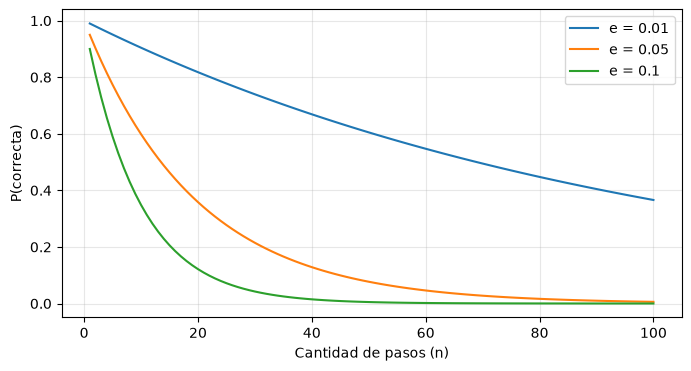

 1 h (6 pasos de 10 min): 53.14%
 4 h (24 pasos de 10 min): 7.98%
10 h (60 pasos de 10 min): 0.18%


In [29]:
# --------------------------
# 6.3) P(correcta) = (1 - e)^n
# --------------------------
n = np.arange(1, 101)
plt.figure(figsize=(8, 4))
for e in [0.01, 0.05, 0.10]:
    plt.plot(n, (1 - e) ** n, label=f"e = {e}")
plt.xlabel("Cantidad de pasos (n)"); plt.ylabel("P(correcta)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

for horas, pasos in [(1, 6), (4, 24), (10, 60)]:
    print(f"{horas:>2} h ({pasos} pasos de 10 min): {100 * 0.9**pasos:.2f}%")

## 7) RAG: Retrieval Augmented Generation

Armamos una base chica de documentos (**datos ficticios para la práctica**), los pasamos a embeddings y, para cada pregunta, recuperamos los más parecidos y se los damos al LLM como contexto.

In [30]:
# --------------------------
# 7.1) Documentos (ficticios)
# --------------------------
docs = [
    # Documentos con la respuesta (gold)
    "Aprendizaje Automático II se dicta los viernes de 18 a 22 h en el aula R101.",
    "Los profesores de Aprendizaje Automático II son Federico Albanese y Franco Castellacci.",
    "El trabajo práctico final de Aprendizaje Automático II se entrega el 27 de noviembre y se hace en grupos de hasta 3 personas.",
    "Para aprobar Aprendizaje Automático II hay que sacar como mínimo 6 en el trabajo práctico final.",
    # Documentos del tema que NO tienen la respuesta (distractores)
    "Aprendizaje Automático I se dicta los martes de 18 a 22 h en el aula R204.",
    "Los profesores de Aprendizaje Automático I son María Gómez y Pablo Ruiz.",
    "El trabajo práctico de Ingeniería de Software se entrega el 13 de noviembre.",
    "Para aprobar Ingeniería de Software hay que sacar como mínimo 4 en el parcial.",
    "Ingeniería de Software se dicta los jueves en el aula R105.",
    # Documentos al azar (ni del tema ni con la respuesta)
    "El dulce de leche se prepara con leche, azúcar y una pizca de bicarbonato.",
    "El río de la Plata es uno de los estuarios más anchos del mundo.",
    "El ajedrez se juega en un tablero de 64 casillas.",
    "Mar del Plata recibe muchos turistas durante el verano.",
]
GOLD, DISTRACT, RANDOM = [0, 1, 2, 3], [4, 5, 6, 7, 8], [9, 10, 11, 12]

# (pregunta, respuesta esperada, índice del documento gold)
qa = [
    ("¿En qué aula se dicta Aprendizaje Automático II?", "R101", 0),
    ("¿Qué día se cursa Aprendizaje Automático II?", "viernes", 0),
    ("¿Quiénes son los profesores de Aprendizaje Automático II?", "Castellacci", 1),
    ("¿Cuándo se entrega el TP final de Aprendizaje Automático II?", "27", 2),
    ("¿Qué nota mínima hay que sacar en el TP final de Aprendizaje Automático II?", "6", 3),
]

def acierta(respuesta, esperado):
    return re.search(r"\b" + re.escape(esperado.lower()) + r"\b", respuesta.lower()) is not None

In [31]:
# --------------------------
# 7.2) Indexar: embeddings + "base de datos vectorial"
# --------------------------
from sentence_transformers import SentenceTransformer

emb_model = SentenceTransformer(EMB_NAME, device=str(device))
emb_docs = emb_model.encode(docs, normalize_embeddings=True)    # [N_docs, 384]

def recuperar(pregunta, k=3):
    q = emb_model.encode([pregunta], normalize_embeddings=True)[0]
    scores = emb_docs @ q                                       # similitud coseno
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top]

for i, s in recuperar(qa[0][0]):
    print(f"{s:.3f} | {docs[i]}")

c:\Projects\MIA\aa2\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\danie\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1164.23it/s]


0.723 | Aprendizaje Automático II se dicta los viernes de 18 a 22 h en el aula R101.
0.691 | Para aprobar Aprendizaje Automático II hay que sacar como mínimo 6 en el trabajo práctico final.
0.688 | Aprendizaje Automático I se dicta los martes de 18 a 22 h en el aula R204.


In [32]:
# --------------------------
# 7.3) Generar con y sin RAG
# --------------------------
def prompt_con_contexto(pregunta, idx_docs):
    ctx = "\n".join(f"Documento [{j+1}]: {docs[i]}" for j, i in enumerate(idx_docs))
    return (f"Respondé usando solo los documentos. Si la respuesta no está, decí 'No sé'.\n\n"
            f"{ctx}\n\nPregunta: {pregunta}")

sin_rag = con_rag = 0
for preg, esp, _ in qa:
    r0 = generar(preg, max_new_tokens=40)
    r1 = generar(prompt_con_contexto(preg, [i for i, _ in recuperar(preg, k=3)]), max_new_tokens=40)
    sin_rag += acierta(r0, esp); con_rag += acierta(r1, esp)
    print(f"{preg}\n  Sin RAG: {r0}\n  Con RAG: {r1}\n")

print(f"Accuracy sin RAG: {sin_rag}/{len(qa)} | con RAG: {con_rag}/{len(qa)}")

¿En qué aula se dicta Aprendizaje Automático II?
  Sin RAG: Aprendizaje Automático II es un curso de aprendizaje avanzado que se desarrolla en una variedad de aulas y centros educativos. Sin embargo, para proporcionar información
  Con RAG: Aprendizaje Automático II se dicta en el aula R101.

¿Qué día se cursa Aprendizaje Automático II?
  Sin RAG: Aprendizaje Automático II es el segundo ciclo de la carrera de Ingeniería en Inteligencia Artificial (IA) en Alibaba Cloud. Este ciclo se realiza desde el 1 de marzo
  Con RAG: El aprendizaje automático II se cursa los viernes de 18 a 22 horas en el aula R101.

¿Quiénes son los profesores de Aprendizaje Automático II?
  Sin RAG: Los profesores de aprendizaje automático II se refieren a los expertos en el campo de la inteligencia artificial y el aprendizaje automático. Estos profesionales tienen una ampl
  Con RAG: Los profesores de Aprendizaje Automático II son María Gómez y Pablo Ruiz.

¿Cuándo se entrega el TP final de Aprendizaje Automátic

### 7.4) The power of noise (Cuconasu et al., 2024)

Armamos el contexto a mano, variando qué documentos acompañan al gold y dónde queda el gold respecto de la pregunta (que va al final del prompt):
- **lejos**: gold primero, después el resto.
- **cerca**: el resto primero, gold justo antes de la pregunta.

Con 5 preguntas los resultados son ruidosos; la idea es ver la tendencia y ampliarla en los ejercicios.

In [33]:
# --------------------------
# 7.4) Gold + distractores / aleatorios, cerca o lejos
# --------------------------
def configs(gold):
    otros_d = [i for i in DISTRACT]
    return {
        "solo gold":              [gold],
        "distractores, gold lejos": [gold] + otros_d,
        "distractores, gold cerca": otros_d + [gold],
        "aleatorios, gold lejos":   [gold] + RANDOM,
        "aleatorios, gold cerca":   RANDOM + [gold],
    }

tabla = {}
for preg, esp, gold in qa:
    for nombre, idx in configs(gold).items():
        r = generar(prompt_con_contexto(preg, idx), max_new_tokens=40)
        tabla.setdefault(nombre, []).append(acierta(r, esp))

print("closed-book (sin docs):", sin_rag, "/", len(qa))
for nombre, oks in tabla.items():
    print(f"{nombre:<26}: {sum(oks)}/{len(oks)}")

closed-book (sin docs): 0 / 5
solo gold                 : 5/5
distractores, gold lejos  : 5/5
distractores, gold cerca  : 3/5
aleatorios, gold lejos    : 5/5
aleatorios, gold cerca    : 5/5


Ejercicios:
1) Evaluar MMLU con otra materia (por ejemplo `high_school_mathematics`) y con un modelo más grande (`Qwen/Qwen2.5-1.5B-Instruct`). ¿Se cumple "a más parámetros, mejor performance"?
2) Comparar pass@k y pass^k para distintas temperaturas (0.3, 0.8, 1.2) y distintos k.
3) LoRA: variar el rango r (1, 4, 16) y agregar el MLP a `target_modules` (`gate_proj`, `up_proj`, `down_proj`). Comparar parámetros entrenables, loss final y si el modelo aprende el dato sin olvidar otras cosas.
4) Sanitización: barrer el umbral y graficar el % de palabras redactadas vs el umbral. Con un clasificador de sentimiento, medir si la sustitución preserva el sentimiento mejor que la redacción.
5) Consistencia: repetir 6.1 con otras preguntas (por ejemplo Malvinas) y con un modelo más grande. ¿Cambia la consistencia entre idiomas?
6) RAG: agregar más documentos y preguntas y repetir 7.4. Implementar búsqueda híbrida con BM25 (`rank_bm25`) para preguntas con siglas o códigos que aparecen una sola vez.